In [528]:
import joblib
from pathlib import Path

# Load the saved model and feature names
model_path = Path("../models/student_performance_model.pkl")
features_path = Path("../models/model_features.pkl")

loaded_model = joblib.load(model_path)
loaded_features = joblib.load(features_path)

# Make a prediction using one test student
sample_student = X_test[loaded_features].iloc[[0]]
prediction = loaded_model.predict(sample_student)[0]

print("Model loaded successfully!")
print("Input features:", loaded_features)
print(f"Predicted final grade: {prediction:.2f}/20")

Model loaded successfully!
Input features: ['age', 'studytime', 'failures', 'absences', 'G1', 'G2']
Predicted final grade: 8.66/20


In [529]:
import joblib
from pathlib import Path

# Locate the project's models folder
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained Random Forest model
joblib.dump(rf_model, models_dir / "student_performance_model.pkl")

# Save the feature names in their exact order
joblib.dump(features, models_dir / "model_features.pkl")

print("Random Forest model saved successfully!")
print("Model location:", models_dir.resolve())

Random Forest model saved successfully!
Model location: C:\Users\Administrator\Desktop\data project\models


In [530]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Generate Random Forest predictions
rf_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Linear Regression": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ],
    "Random Forest": [
        mean_absolute_error(y_test, rf_pred),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
        r2_score(y_test, rf_pred)
    ]
})

print(comparison.round(3))

     Metric  Linear Regression  Random Forest
0       MAE              1.334          1.038
1      RMSE              2.112          1.732
2  R² Score              0.782          0.854


In [531]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


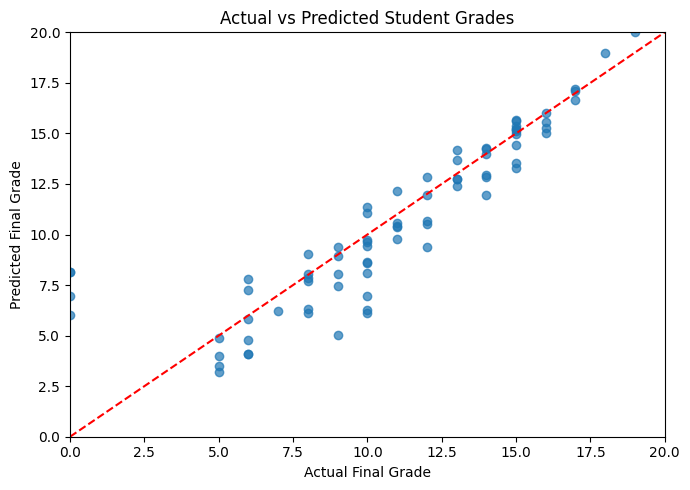

In [532]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
plt.plot([0, 20], [0, 20], "r--")

plt.title("Actual vs Predicted Student Grades")
plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.tight_layout()
plt.show()

In [533]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error (MAE): 1.33
Root Mean Squared Error (RMSE): 2.11
R² Score: 0.78


In [534]:
# Predict final grades using the testing data
y_pred = model.predict(X_test)

# Display actual and predicted grades
results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": y_pred
})

print(results.head(10).round(2))

   Actual Grade  Predicted Grade
0            10             6.12
1            12            11.97
2             5             3.20
3            10             8.61
4             9             7.43
5            13            12.42
6            18            18.99
7             6             7.27
8             0             6.95
9            14            12.87


In [535]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [536]:
from sklearn.model_selection import train_test_split

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (316, 6)
Testing features: (79, 6)
Training target: (316,)
Testing target: (79,)


In [537]:
# Select the input features for prediction
features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = students_clean[features]
y = students_clean["G3"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)
print("\nSelected features:")
print(X.columns.tolist())
print("\nTarget variable: G3 (final grade)")

Input features shape: (395, 6)
Target variable shape: (395,)

Selected features:
['age', 'studytime', 'failures', 'absences', 'G1', 'G2']

Target variable: G3 (final grade)


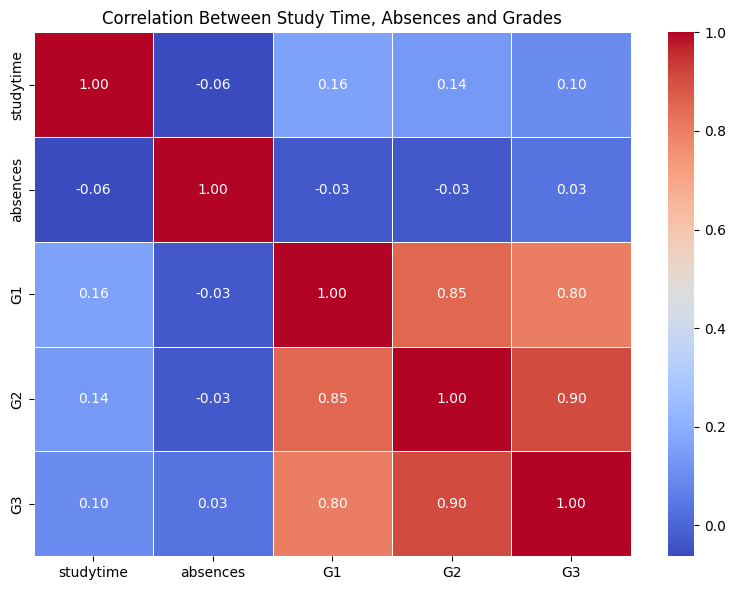

In [538]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlations
correlation = students_clean[
    ["studytime", "absences", "G1", "G2", "G3"]
].corr()

# Create the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Study Time, Absences and Grades")
plt.tight_layout()
plt.show()

In [539]:
# Calculate correlations between selected variables
correlation = students_clean[["studytime", "absences", "G1", "G2", "G3"]].corr()

correlation

,studytime,absences,G1,G2,G3
studytime,1.000000,-0.062700,0.160612,0.135880,0.097820
absences,-0.062700,1.000000,-0.031003,-0.031777,0.034247
G1,0.160612,-0.031003,1.000000,0.852118,0.801468
G2,0.135880,-0.031777,0.852118,1.000000,0.904868
G3,0.097820,0.034247,0.801468,0.904868,1.000000


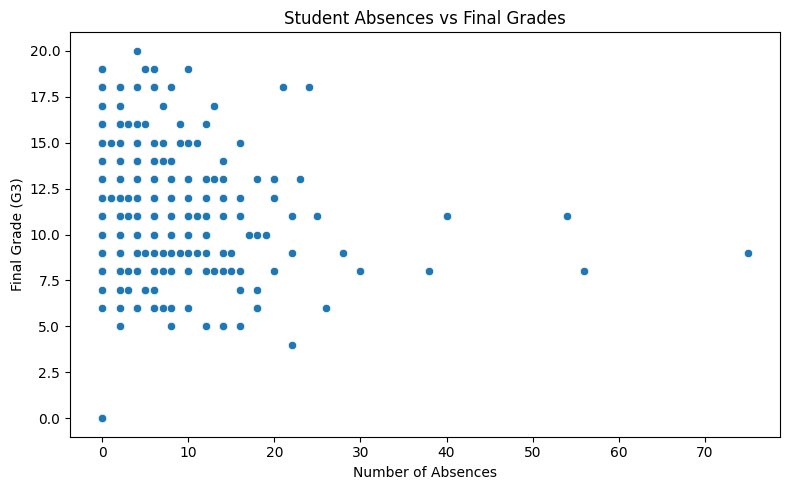

In [540]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=students_clean,
    x="absences",
    y="G3"
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()
plt.show()

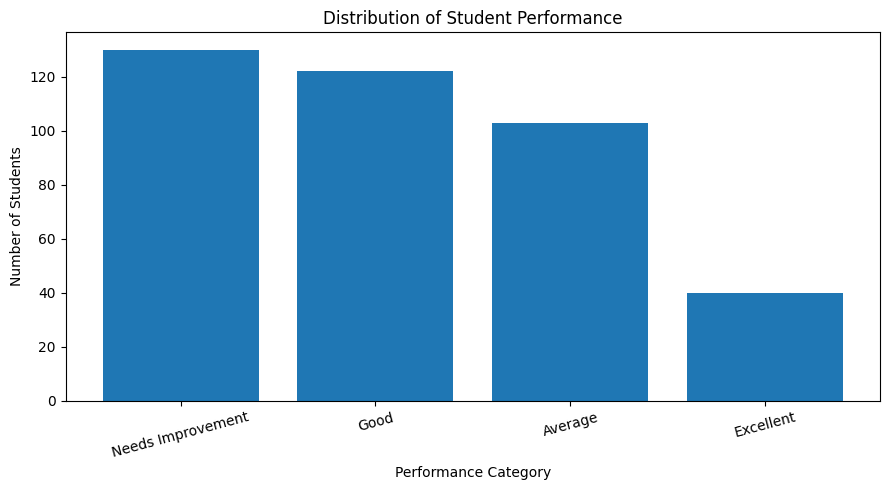

In [541]:
import matplotlib.pyplot as plt

# Create performance categories
def categorize_grade(grade):
    if grade >= 16:
        return "Excellent"
    elif grade >= 12:
        return "Good"
    elif grade >= 10:
        return "Average"
    else:
        return "Needs Improvement"

# Add the column to the cleaned dataset
students_clean["Performance"] = students_clean["G3"].apply(categorize_grade)

# Count students in each category
performance_counts = students_clean["Performance"].value_counts()

# Create the bar chart
plt.figure(figsize=(9, 5))
plt.bar(performance_counts.index, performance_counts.values)

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

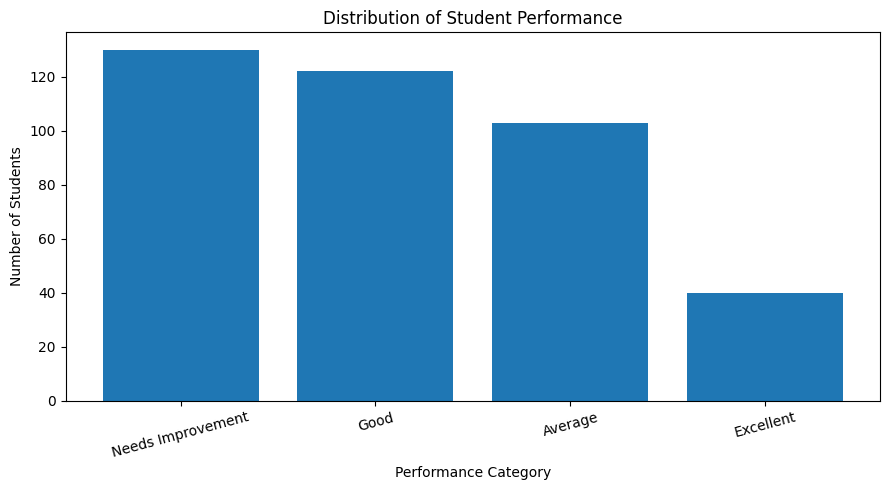

In [542]:
import matplotlib.pyplot as plt

# Create performance categories
def categorize_grade(grade):
    if grade >= 16:
        return "Excellent"
    elif grade >= 12:
        return "Good"
    elif grade >= 10:
        return "Average"
    else:
        return "Needs Improvement"

# Add the column to the cleaned dataset
students_clean["Performance"] = students_clean["G3"].apply(categorize_grade)

# Count students in each category
performance_counts = students_clean["Performance"].value_counts()

# Create the bar chart
plt.figure(figsize=(9, 5))
plt.bar(performance_counts.index, performance_counts.values)

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [543]:
print(students_clean.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'Performance']


In [544]:
print(students_clean["Performance"].value_counts())

Performance
Needs Improvement    130
Good                 122
Average              103
Excellent             40
Name: count, dtype: int64


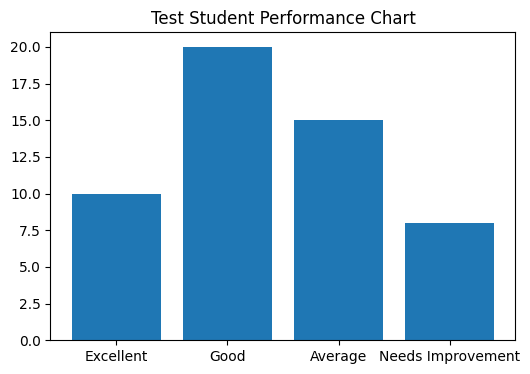

Chart test completed


In [545]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.bar(["Excellent", "Good", "Average", "Needs Improvement"], [10, 20, 15, 8])
plt.title("Test Student Performance Chart")
plt.show()

print("Chart test completed")

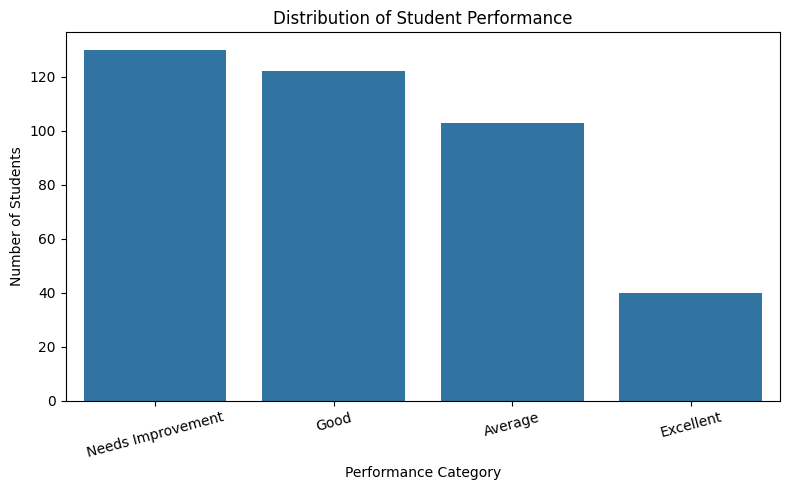

In [546]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count students in each performance category
performance_counts = students_clean["Performance"].value_counts()

# Draw the bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=performance_counts.index,
    y=performance_counts.values
)

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [547]:
# Create performance categories again
def categorize_grade(grade):
    if grade >= 16:
        return "Excellent"
    elif grade >= 12:
        return "Good"
    elif grade >= 10:
        return "Average"
    else:
        return "Needs Improvement"

students_clean["Performance"] = students_clean["G3"].apply(categorize_grade)

# Display the number of students in each category
print(students_clean["Performance"].value_counts())

Performance
Needs Improvement    130
Good                 122
Average              103
Excellent             40
Name: count, dtype: int64


In [548]:
# Group final grades into performance categories
def categorize_grade(grade):
    if grade >= 16:
        return "Excellent"
    elif grade >= 12:
        return "Good"
    elif grade >= 10:
        return "Average"
    else:
        return "Needs Improvement"

students_clean["Performance"] = students_clean["G3"].apply(categorize_grade)

students_clean["Performance"].value_counts()

Performance
Needs Improvement    130
Good                 122
Average              103
Excellent             40
Name: count, dtype: int64

In [549]:
# Calculate average grades
print("Average first-period grade:", students_clean["G1"].mean())
print("Average second-period grade:", students_clean["G2"].mean())
print("Average final grade:", students_clean["G3"].mean())

Average first-period grade: 10.90886075949367
Average second-period grade: 10.713924050632912
Average final grade: 10.415189873417722


In [550]:
# Create a clean copy of the dataset
students_clean = students.copy()

# Remove duplicate rows if any exist
students_clean = students_clean.drop_duplicates()

# Confirm the cleaned dataset
print("Original dataset shape:", students.shape)
print("Cleaned dataset shape:", students_clean.shape)
print("Missing values:", students_clean.isnull().sum().sum())
print("Duplicate rows:", students_clean.duplicated().sum())

Original dataset shape: (395, 33)
Cleaned dataset shape: (395, 33)
Missing values: 0
Duplicate rows: 0


In [551]:
# Check the minimum and maximum grades
students[["G1", "G2", "G3"]].agg(["min", "max"])

,G1,G2,G3
min,3,0,0
max,19,19,20


In [552]:
# Summary statistics for numerical columns
students.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [553]:
# Check the data type of each column
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [554]:
# Count duplicate rows
students.duplicated().sum()

np.int64(0)

In [555]:
# Check for missing values in each column
students.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [556]:
students.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [557]:
students.shape


(395, 33)

In [558]:
students.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [559]:
# Display the first five student records
students.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [560]:
import pandas as pd

print("Pandas is ready!")

Pandas is ready!


In [561]:
import pandas as pd

# Load the mathematics student dataset
students = pd.read_csv("../data/student-mat.csv", sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Student Performance Analysis and Prediction

## Phase 3: Data Loading

This notebook loads and explores the student mathematics dataset.